# Calculator kit

A calculator UI from layout groups: keys are `VStack`s, the keypad a `Grid`, the display and the keypad
stack inside the shell. Every control re-lays out the whole calculator, because each group sizes itself
to its content.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from animations import press
from components import FONTS, LAYOUTS, SHAPES, SHELLS, display, key, keypad, shell

The project's theme applies to everything below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)
theme.__enter__();

In [3]:
PALETTES = {"tangerine": "#f97316", "indigo": "#4f46e5", "teal": "#0d9488", "rose": "#e11d48",
            "graphite": "#3f3f46"}
WEIGHTS = {"light": 300, "regular": 400, "medium": 500, "bold": 700}
DESK = 40          # desk margin around the calculator
GLASS_BLOBS = (("#f472b6", 0.15, 0.2, 0.45), ("#38bdf8", 0.85, 0.35, 0.5), ("#facc15", 0.4, 0.9, 0.4))
# colour, x, y (shares of the desk) and radius (share of the width) of the blobs behind a glass shell

The controls: rows of buttons for the styles, sliders for the spacing, a toggle for the history line and
swatches for the accent colour.

In [4]:
@svg.widgets.controls(
    style=svg.widgets.Segmented(list(SHELLS), value="default", label="shell"),
    shape=svg.widgets.Segmented(list(SHAPES), value="round", label="key shape"),
    layout=svg.widgets.Segmented(list(LAYOUTS), value="standard 4x5"),
    font=svg.widgets.Segmented(list(FONTS), value="grotesk", label="display font"),
    size=svg.widgets.Slider(24, 64, step=2, value=44, label="display size"),
    align=svg.widgets.Segmented(["left", "center", "right"], value="right"),
    history=svg.widgets.Toggle(True, label="show history"),
    key_font=svg.widgets.Segmented(list(FONTS), value="grotesk", label="key labels"),
    weight=svg.widgets.Segmented(WEIGHTS, value=500, label="key weight"),
    padding=svg.widgets.Slider(8, 40, step=1, value=20),
    gap=svg.widgets.Slider(2, 20, step=1, value=10, label="key gap"),
    key_height=svg.widgets.Slider(36, 80, step=2, value=56, label="key height"),
    radius=svg.widgets.Slider(0, 40, step=1, value=28, label="corner radius"),
    width=svg.widgets.Slider(260, 520, step=10, value=320),
    accent=svg.widgets.Swatches(PALETTES, value="#f97316", label="palette"),
)
def calculator(doc: svg.Document, *, style: str = "default", shape: str = "round", layout: str = "standard 4x5",
               font: str = "grotesk", size: float = 44, align: str = "right", history: bool = True,
               key_font: str = "grotesk", weight: int = 500, padding: float = 20, gap: float = 10,
               key_height: float = 56, radius: float = 28, width: float = 320,
               accent: str = "#f97316") -> svg.Document:
    """Draw the calculator on a desk into *doc* and size the page to the desk."""
    palette = doc.theme.palette
    tint = svg.Color.parse(accent)
    colors = {"digit": (palette["digit"], palette["foreground"]),
              "function": (palette["function"], palette["foreground"]),
              "operator": (tint, tint.readable())}

    def make_key(label: str) -> svg.VStack:
        return key(label, shape=shape, height=key_height, colors=colors, font=FONTS[key_font], weight=weight)

    pad = keypad(layout, make_key, gap=gap, align="center" if shape == "circle" else "stretch")
    screen = display("1,234.56", "1,200 + 34.56" if history else None, font=font, size=size, align=align,
                     radius=max(radius - padding / 2, 0))
    body = svg.VStack(screen, pad, gap=gap * 1.6, padding=padding, align="stretch", width=width,
                      background=shell(style, radius=radius, accent=tint))

    desk = doc.rect(0, 0, 1, 1).as_role("desk")
    blobs = doc.group() if style == "glass" else None
    doc += body
    body.matrix = svg.Matrix.translate(DESK, DESK)
    box = body.bounds()
    desk.width, desk.height = box.width + 2 * DESK, box.height + 2 * DESK
    doc.fit()
    if blobs is not None:
        for color, x, y, r in GLASS_BLOBS:
            blobs += svg.circle(desk.width * x, desk.height * y, width * r, fill=color)
        blobs.filter = svg.filters.blur(width * 0.12)
    equals = next(child for child in pad.children if "=" in child.to_string())
    equals.animate.apply(press, begin=1)
    return doc

Every control of `calculator` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [5]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(calculator))

The same function for other control values.

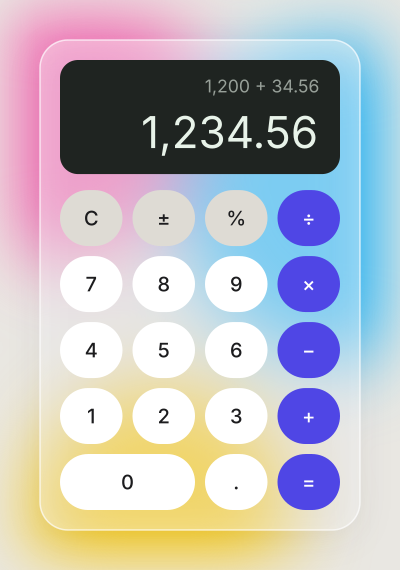

In [6]:
show(calculator, **{'style': 'glass', 'accent': '#4f46e5', 'shape': 'pill'})

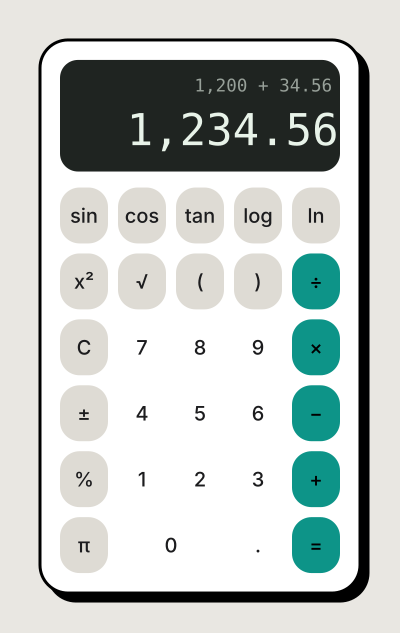

In [7]:
show(calculator, **{'style': 'brutal', 'layout': 'scientific 5x6', 'font': 'mono', 'accent': '#0d9488'})

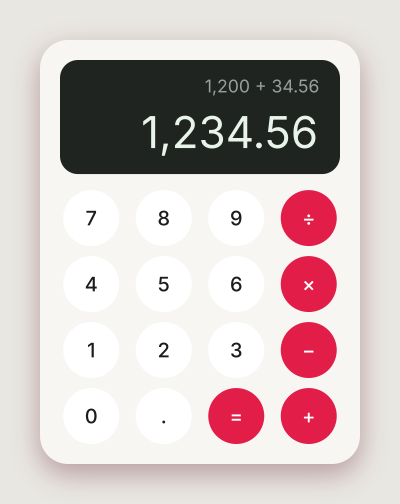

In [8]:
show(calculator, **{'style': 'soft', 'layout': 'compact 4x4', 'shape': 'circle', 'accent': '#e11d48'})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

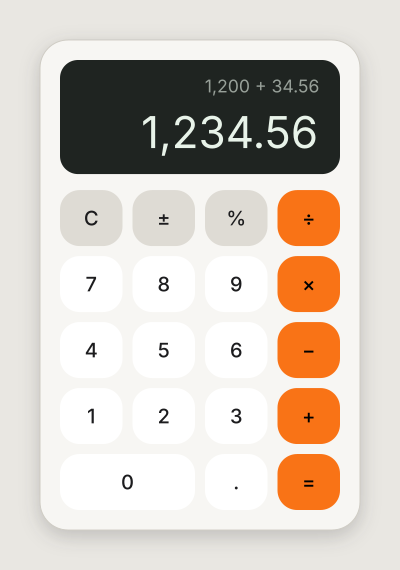

In [9]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))